# SmartCanteen – Food Demand Prediction

### Foundations of Data Science Project

SmartCanteen is a Data Science and Machine Learning project designed to analyze canteen sales data and predict the expected demand for food items.

The project includes data analysis, exploratory data visualization, machine learning model training, model comparison, and food demand prediction.

## 1. Import Libraries

The required Python libraries are imported for data analysis, visualization, preprocessing, machine learning, and model evaluation.

In [537]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Load Dataset

The canteen dataset is loaded into a Pandas DataFrame for further analysis and machine learning.

In [538]:
# Load the dataset

df = pd.read_csv("canteen_data.csv")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (2190, 14)


### Dataset Preview

The first few records are displayed to understand the structure and values of the dataset.

In [539]:
# Display first five records

df.head()

,Date,Day,Weather,Temperature,Rainfall_mm,Exam_Day,Holiday,Students,Food_Item,Price,Quantity_Prepared,Quantity_Sold,Waste_Quantity,Revenue
0,2025-08-18,Monday,Sunny,28,0.0,1,0,778,Vada Pav,20,118,104,14,2080
1,2026-04-09,Thursday,Cloudy,26,4.7,1,0,773,Samosa,15,138,126,12,1890
2,2026-03-23,Monday,Cloudy,26,2.7,0,0,741,Samosa,15,124,116,8,1740
3,2025-09-02,Tuesday,Cloudy,31,1.5,1,0,737,Maggi,35,89,79,10,2765
4,2026-04-30,Thursday,Sunny,28,0.0,1,0,956,Samosa,15,182,164,18,2460


## 3. Dataset Overview

The dataset structure is examined to understand the number of records, columns, data types, and basic statistical information.

In [540]:
# Display dataset information

print("Dataset Information")
print("=" * 50)

print("Number of Records:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

Dataset Information
Number of Records: 2190
Number of Columns: 14

Column Names:
['Date', 'Day', 'Weather', 'Temperature', 'Rainfall_mm', 'Exam_Day', 'Holiday', 'Students', 'Food_Item', 'Price', 'Quantity_Prepared', 'Quantity_Sold', 'Waste_Quantity', 'Revenue']

Data Types:


Date                     str
Day                      str
Weather                  str
Temperature            int64
Rainfall_mm          float64
Exam_Day               int64
Holiday                int64
Students               int64
Food_Item                str
Price                  int64
Quantity_Prepared      int64
Quantity_Sold          int64
Waste_Quantity         int64
Revenue                int64
dtype: object

### Statistical Summary

Basic statistical measures are calculated for the numerical variables in the dataset.

In [541]:
# Display statistical summary

df.describe()

,Temperature,Rainfall_mm,Exam_Day,Holiday,Students,Price,Quantity_Prepared,Quantity_Sold,Waste_Quantity,Revenue
count,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000,2190.000000
mean,28.920548,8.360274,0.216438,0.101370,643.646575,24.166667,96.225571,87.469863,8.755708,1741.616438
std,3.290709,14.495467,0.411911,0.301887,265.391839,10.576230,76.290992,69.394436,7.561966,1007.194682
min,22.000000,0.000000,0.000000,0.000000,51.000000,10.000000,0.000000,0.000000,0.000000,0.000000
25%,26.000000,0.000000,0.000000,0.000000,415.000000,15.000000,39.000000,35.000000,3.000000,760.000000
50%,29.000000,0.700000,0.000000,0.000000,740.000000,22.500000,84.000000,77.000000,7.000000,1950.000000
75%,31.000000,7.000000,0.000000,0.000000,858.000000,35.000000,124.000000,113.000000,12.000000,2497.500000
max,35.000000,59.700000,1.000000,1.000000,1000.000000,40.000000,429.000000,399.000000,51.000000,4410.000000


## 4. Data Quality Check

The dataset is checked for missing values and duplicate records to ensure that the data is suitable for further analysis and model training.

In [542]:
# Check for missing values and duplicate records

print("Missing Values")
print("=" * 50)
display(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

print("\nDuplicate Records")
print("=" * 50)
print("Total Duplicate Records:", df.duplicated().sum())

Missing Values


Date                 0
Day                  0
Weather              0
Temperature          0
Rainfall_mm          0
Exam_Day             0
Holiday              0
Students             0
Food_Item            0
Price                0
Quantity_Prepared    0
Quantity_Sold        0
Waste_Quantity       0
Revenue              0
dtype: int64


Total Missing Values: 0

Duplicate Records
Total Duplicate Records: 0


### Data Quality Result

The dataset contains no missing values and no duplicate records. Therefore, the dataset is suitable for further exploratory analysis and machine learning.

## 5. Exploratory Data Analysis

Exploratory Data Analysis (EDA) is performed to understand food demand patterns and identify relationships between food items, student count, weather conditions, and other factors.

### 5.1 Food Item Distribution

The number of records for each food item is analyzed to understand the distribution of different food items in the dataset.

In [543]:
# Analyze food item distribution

food_counts = df["Food_Item"].value_counts()

print("Food Item Distribution")
print("=" * 50)
display(food_counts)

Food Item Distribution


Food_Item
Vada Pav      365
Samosa        365
Maggi         365
Sandwich      365
Cold Drink    365
Tea           365
Name: count, dtype: int64

### Food Item Distribution Visualization

A bar chart is used to visualize the number of records available for each food item.

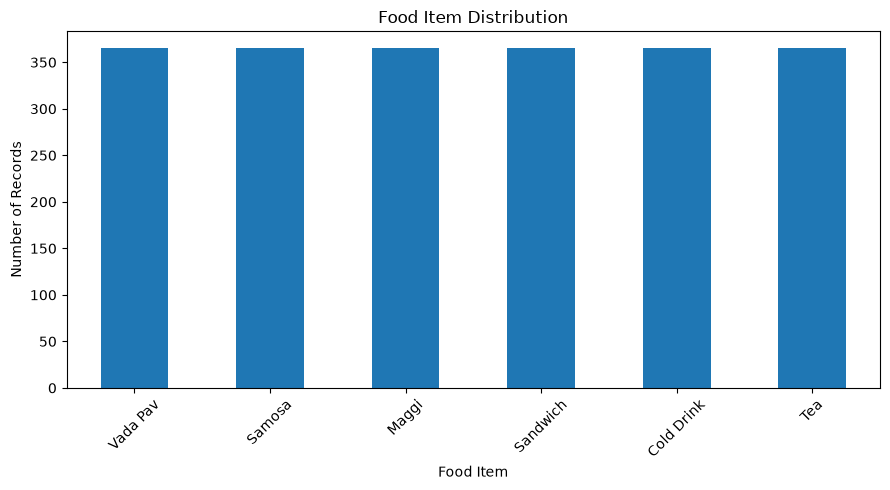

In [544]:
# Plot food item distribution

plt.figure(figsize=(9, 5))

food_counts.plot(kind="bar")

plt.title("Food Item Distribution")
plt.xlabel("Food Item")
plt.ylabel("Number of Records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.2 Food Demand Analysis

The total quantity sold for each food item is analyzed to identify demand patterns across different food items.

In [545]:
# Calculate total quantity sold by food item

food_demand = (
    df.groupby("Food_Item")["Quantity_Sold"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Food Demand by Item")
print("=" * 50)
display(food_demand)

Total Food Demand by Item


Food_Item
Tea           65528
Samosa        33121
Vada Pav      28673
Cold Drink    25043
Maggi         21050
Sandwich      18144
Name: Quantity_Sold, dtype: int64

### Food Demand Visualization

A bar chart is used to compare the total quantity sold for each food item and identify the relative demand for different items.

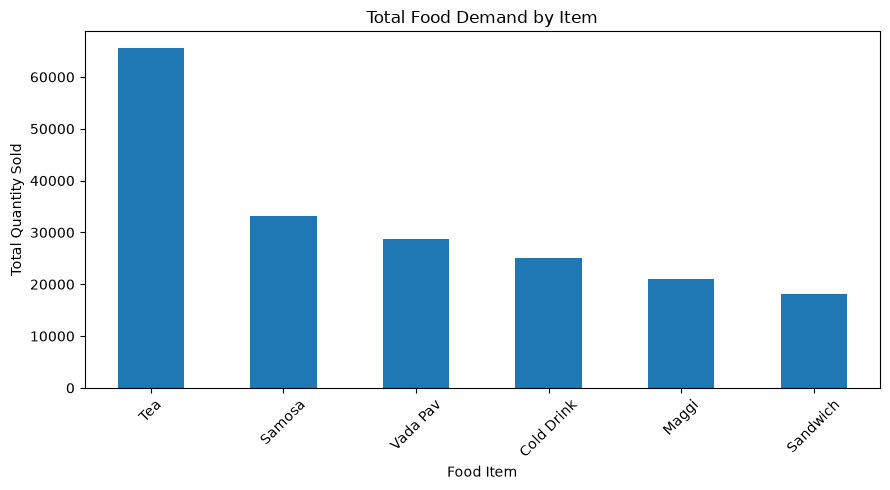

In [546]:
# Plot total food demand

plt.figure(figsize=(9, 5))

food_demand.plot(kind="bar")

plt.title("Total Food Demand by Item")
plt.xlabel("Food Item")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.3 Student Count and Food Demand

The relationship between the number of students and food demand is analyzed to understand whether student footfall affects the quantity of food sold.

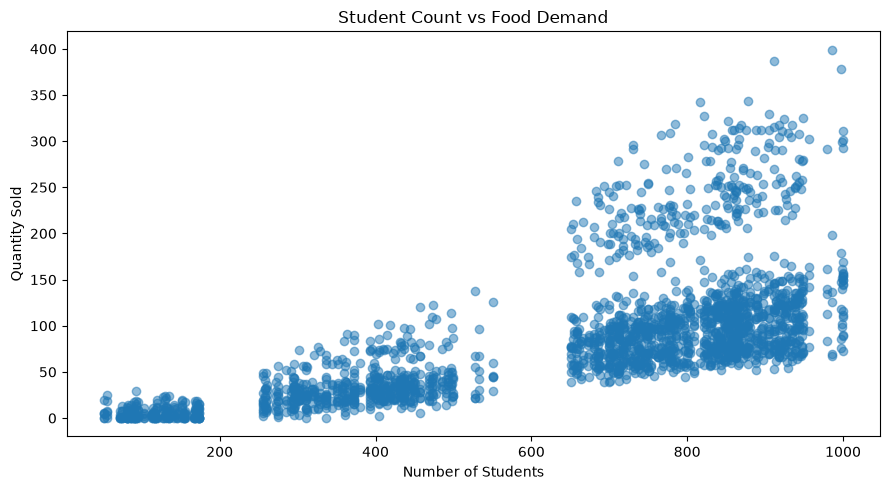

In [547]:
# Analyze student count and food demand

plt.figure(figsize=(9, 5))

plt.scatter(
    df["Students"],
    df["Quantity_Sold"],
    alpha=0.5
)

plt.title("Student Count vs Food Demand")
plt.xlabel("Number of Students")
plt.ylabel("Quantity Sold")
plt.tight_layout()
plt.show()

### 5.4 Weather and Food Demand

The average food demand is compared across different weather conditions to understand how weather may affect canteen sales.

In [548]:
# Calculate average demand by weather condition

weather_demand = (
    df.groupby("Weather")["Quantity_Sold"]
    .mean()
    .sort_values(ascending=False)
)

print("Average Food Demand by Weather")
print("=" * 50)
display(weather_demand.round(2))

Average Food Demand by Weather


Weather
Rainy     97.82
Sunny     85.64
Cloudy    82.49
Name: Quantity_Sold, dtype: float64

### Weather Demand Visualization

A bar chart is used to compare the average quantity sold under different weather conditions.

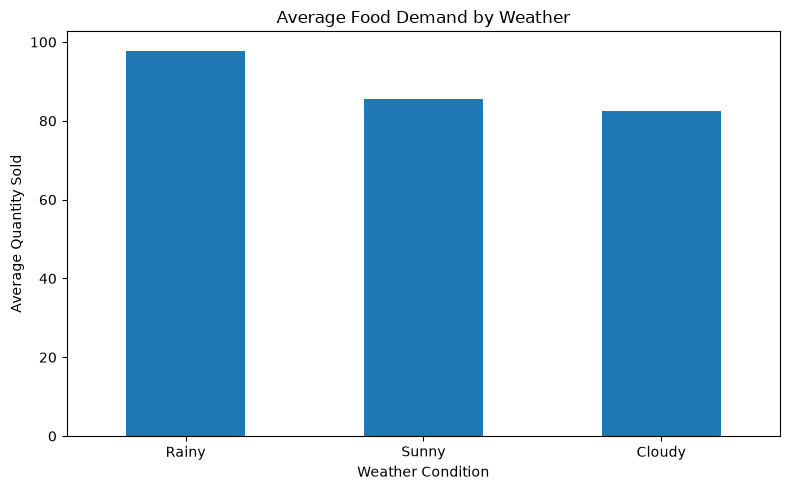

In [549]:
# Plot average demand by weather

plt.figure(figsize=(8, 5))

weather_demand.plot(kind="bar")

plt.title("Average Food Demand by Weather")
plt.xlabel("Weather Condition")
plt.ylabel("Average Quantity Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.5 Exam Day vs Normal Day

The average food demand on examination days is compared with normal days to understand whether examination schedules influence canteen sales.

In [550]:
# Calculate average demand for exam and normal days

exam_demand = (
    df.groupby("Exam_Day")["Quantity_Sold"]
    .mean()
)

print("Average Food Demand: Exam Day vs Normal Day")
print("=" * 50)

exam_demand.index = exam_demand.index.map({
    0: "Normal Day",
    1: "Exam Day"
})

display(exam_demand.round(2))

Average Food Demand: Exam Day vs Normal Day


Exam_Day
Normal Day     80.95
Exam Day      111.07
Name: Quantity_Sold, dtype: float64

### Exam Day Demand Visualization

A bar chart is used to compare the average food demand between examination days and normal days.

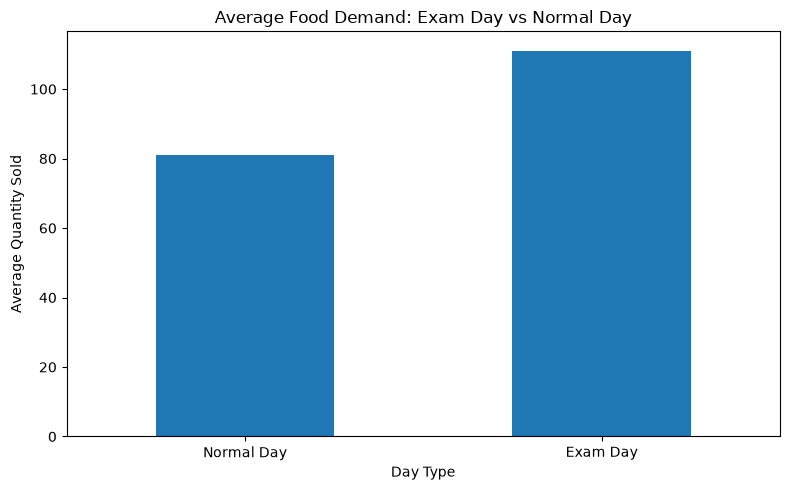

In [551]:
# Plot exam day vs normal day demand

plt.figure(figsize=(8, 5))

exam_demand.plot(kind="bar")

plt.title("Average Food Demand: Exam Day vs Normal Day")
plt.xlabel("Day Type")
plt.ylabel("Average Quantity Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### 5.6 Food Waste Analysis

Food waste is analyzed by comparing the quantity of food prepared with the quantity sold for each food item. This helps identify items where more food remains unsold.

In [552]:
# Calculate total prepared, sold and wasted quantity by food item

waste_analysis = (
    df.groupby("Food_Item")[
        ["Quantity_Prepared", "Quantity_Sold", "Waste_Quantity"]
    ]
    .sum()
    .sort_values("Waste_Quantity", ascending=False)
)

print("Food Waste Analysis")
print("=" * 50)

display(waste_analysis)

Food Waste Analysis


,Quantity_Prepared,Quantity_Sold,Waste_Quantity
Food_Item,,,
Tea,72023,65528,6495
Samosa,36515,33121,3394
Vada Pav,31520,28673,2847
Cold Drink,27533,25043,2490
Maggi,23136,21050,2086
Sandwich,20007,18144,1863


### Waste Visualization

The following chart compares the quantity prepared, quantity sold, and quantity wasted for each food item.

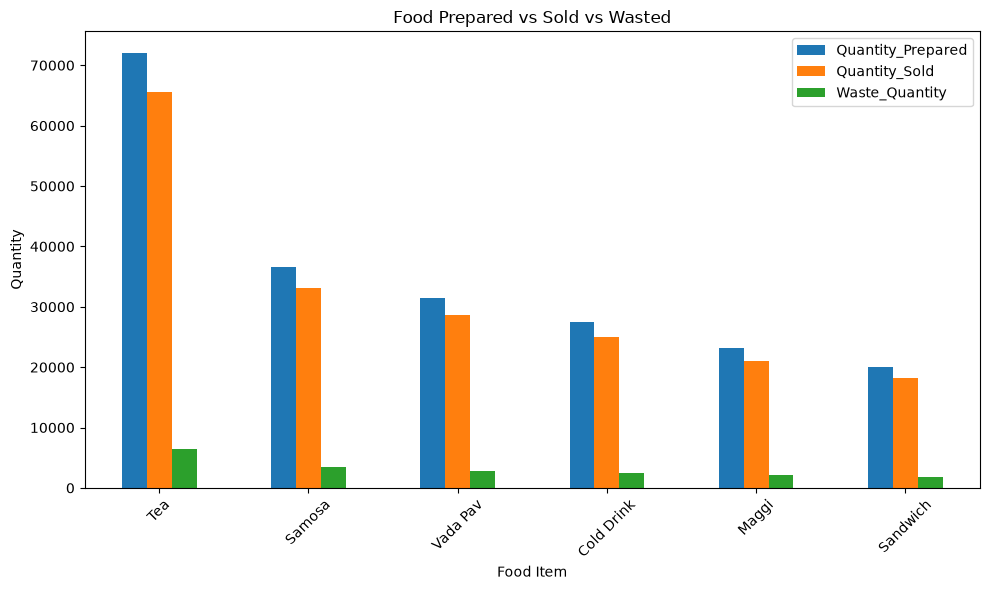

In [553]:
# Plot prepared, sold and wasted quantity

waste_analysis.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Food Prepared vs Sold vs Wasted")
plt.xlabel("Food Item")
plt.ylabel("Quantity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.7 Revenue Analysis

Revenue is analyzed for each food item to understand the contribution of different food items to the total canteen revenue.

In [554]:
# Calculate total revenue by food item

revenue_analysis = (
    df.groupby("Food_Item")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Revenue by Food Item")
print("=" * 50)

display(revenue_analysis)

Total Revenue by Food Item


Food_Item
Maggi         736750
Sandwich      725760
Tea           655280
Cold Drink    626075
Vada Pav      573460
Samosa        496815
Name: Revenue, dtype: int64

### Revenue Visualization

The following bar chart shows the total revenue generated by each food item.

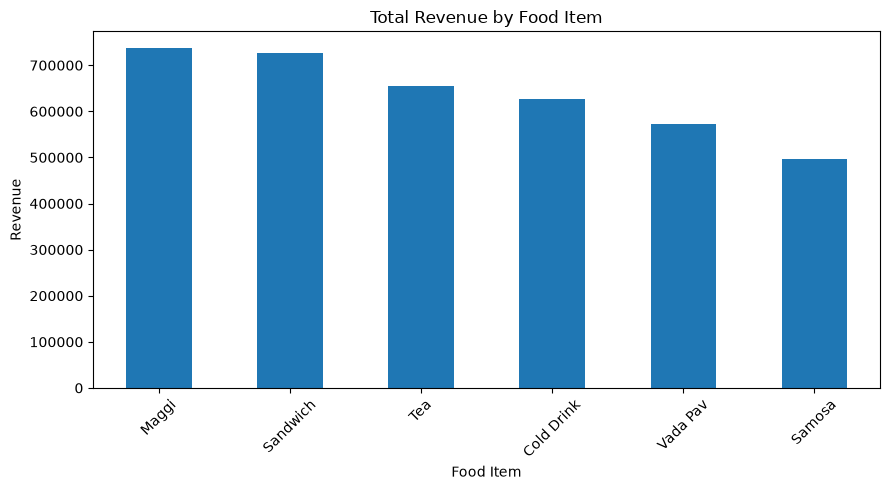

In [555]:
# Plot total revenue by food item

plt.figure(figsize=(9, 5))

revenue_analysis.plot(kind="bar")

plt.title("Total Revenue by Food Item")
plt.xlabel("Food Item")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 5.8 Exploratory Data Analysis Summary

The exploratory analysis provided useful insights into food demand and canteen sales patterns.

- Food demand varies across different food items.
- Student count shows a relationship with food demand.
- Weather conditions show differences in average food demand.
- Examination days show higher average demand than normal days in the dataset.
- The prepared, sold, and wasted quantities were compared to understand food waste.
- Revenue analysis was performed for each food item.

These findings provide a useful basis for the machine learning stage, where food demand will be predicted using relevant features.

# 6. Machine Learning – Food Demand Prediction

Machine Learning is used to predict the expected quantity of food that may be sold based on historical canteen data.

Different regression algorithms are trained and compared to identify a suitable model for food demand prediction.

## 6.1 Feature and Target Selection

The input features are selected based on the factors that may influence food demand.

The target variable is `Quantity_Sold`, which represents the actual quantity of food sold.

In [556]:
# Define input features and target variable

features = [
    "Day",
    "Weather",
    "Temperature",
    "Rainfall_mm",
    "Exam_Day",
    "Holiday",
    "Students",
    "Food_Item",
    "Price"
]

target = "Quantity_Sold"

X = df[features]
y = df[target]

print("Features:")
print(features)

print("\nTarget Variable:")
print(target)

print("\nFeature Shape:", X.shape)
print("Target Shape:", y.shape)

Features:
['Day', 'Weather', 'Temperature', 'Rainfall_mm', 'Exam_Day', 'Holiday', 'Students', 'Food_Item', 'Price']

Target Variable:
Quantity_Sold

Feature Shape: (2190, 9)
Target Shape: (2190,)


## 6.2 Train-Test Split

The dataset is divided into training and testing sets.

- 80% of the data is used for training the machine learning models.
- 20% of the data is used for testing the model performance.

A fixed random state is used to make the results reproducible.

In [557]:
# Split the dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 1752
Testing Records: 438


## 6.3 Data Preprocessing

The dataset contains both numerical and categorical features.

Categorical variables are converted into numerical form using One-Hot Encoding, while numerical variables are passed directly to the machine learning models.

A preprocessing pipeline is used so that the same transformations are applied consistently during training and prediction.

In [558]:
# Identify numerical and categorical features

categorical_features = [
    "Day",
    "Weather",
    "Food_Item"
]

numerical_features = [
    "Temperature",
    "Rainfall_mm",
    "Exam_Day",
    "Holiday",
    "Students",
    "Price"
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Day', 'Weather', 'Food_Item']

Numerical Features:
['Temperature', 'Rainfall_mm', 'Exam_Day', 'Holiday', 'Students', 'Price']


### Preprocessing Pipeline

The preprocessing pipeline uses One-Hot Encoding for categorical features.

The `handle_unknown="ignore"` option allows the model to handle any new category that may appear during prediction.

In [559]:
# Create preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


## 6.4 Linear Regression Model

Linear Regression is used as a baseline regression model for predicting food demand.

It attempts to model the relationship between the input features and the quantity of food sold.

In [560]:
# Create Linear Regression pipeline

linear_regression_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train the model

linear_regression_model.fit(X_train, y_train)

# Make predictions

linear_predictions = linear_regression_model.predict(X_test)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


### Linear Regression Evaluation

The model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

In [561]:
# Evaluate Linear Regression

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Performance")
print("=" * 50)
print("MAE :", round(linear_mae, 4))
print("RMSE:", round(linear_rmse, 4))
print("R²  :", round(linear_r2, 4))

Linear Regression Performance
MAE : 19.6591
RMSE: 27.8875
R²  : 0.8162


## 6.5 Decision Tree Regression

Decision Tree Regression is used to model non-linear relationships between the input features and food demand.

The model splits the data into different decision rules and predicts the expected quantity sold.

In [562]:
# Create Decision Tree Regression pipeline

decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(random_state=42))
    ]
)

# Train the model

decision_tree_model.fit(X_train, y_train)

# Make predictions

decision_tree_predictions = decision_tree_model.predict(X_test)

print("Decision Tree Regression model trained successfully!")

Decision Tree Regression model trained successfully!


### Decision Tree Regression Evaluation

The Decision Tree model is evaluated using MAE, RMSE, and R² Score.

In [563]:
# Evaluate Decision Tree Regression

decision_tree_mae = mean_absolute_error(
    y_test,
    decision_tree_predictions
)

decision_tree_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        decision_tree_predictions
    )
)

decision_tree_r2 = r2_score(
    y_test,
    decision_tree_predictions
)

print("Decision Tree Regression Performance")
print("=" * 50)
print("MAE :", round(decision_tree_mae, 4))
print("RMSE:", round(decision_tree_rmse, 4))
print("R²  :", round(decision_tree_r2, 4))

Decision Tree Regression Performance
MAE : 10.355
RMSE: 13.1459
R²  : 0.9592


## 6.6 Random Forest Regression

Random Forest Regression is an ensemble machine learning algorithm that combines multiple decision trees to produce a more accurate prediction.

It is used in this project to predict food demand based on student count, food item, weather, temperature, rainfall, examination day, holiday, and price.

The Random Forest model will be evaluated using MAE, RMSE, and R² Score.

In [564]:
# Create Random Forest Regression pipeline

random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=100,
            random_state=42
        ))
    ]
)

# Train the model

random_forest_model.fit(X_train, y_train)

# Make predictions

random_forest_predictions = random_forest_model.predict(X_test)

print("Random Forest Regression model trained successfully!")

Random Forest Regression model trained successfully!


### Random Forest Regression Evaluation

The Random Forest model is evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

In [565]:
# Evaluate Random Forest Regression

random_forest_mae = mean_absolute_error(
    y_test,
    random_forest_predictions
)

random_forest_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        random_forest_predictions
    )
)

random_forest_r2 = r2_score(
    y_test,
    random_forest_predictions
)

print("Random Forest Regression Performance")
print("=" * 50)
print("MAE :", round(random_forest_mae, 4))
print("RMSE:", round(random_forest_rmse, 4))
print("R²  :", round(random_forest_r2, 4))

Random Forest Regression Performance
MAE : 7.894
RMSE: 9.9328
R²  : 0.9767


## 6.7 Model Comparison

Three regression models were trained and evaluated for food demand prediction:

- Linear Regression
- Decision Tree Regression
- Random Forest Regression

The models are compared using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

In [566]:
# Create model comparison table

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        linear_mae,
        decision_tree_mae,
        random_forest_mae
    ],
    "RMSE": [
        linear_rmse,
        decision_tree_rmse,
        random_forest_rmse
    ],
    "R2 Score": [
        linear_r2,
        decision_tree_r2,
        random_forest_r2
    ]
})

model_comparison.round(4)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,19.6591,27.8875,0.8162
1,Decision Tree,10.3550,13.1459,0.9592
2,Random Forest,7.8940,9.9328,0.9767


### Model Performance Comparison

Lower MAE and RMSE indicate lower prediction error, while a higher R² Score indicates better model performance.

In [567]:
# Display model performance comparison

display(
    model_comparison.round(4)
)

,Model,MAE,RMSE,R2 Score
0,Linear Regression,19.6591,27.8875,0.8162
1,Decision Tree,10.3550,13.1459,0.9592
2,Random Forest,7.8940,9.9328,0.9767


### R² Score Comparison

The R² Score of the three models is visualized to compare how well each model explains the variation in food demand.

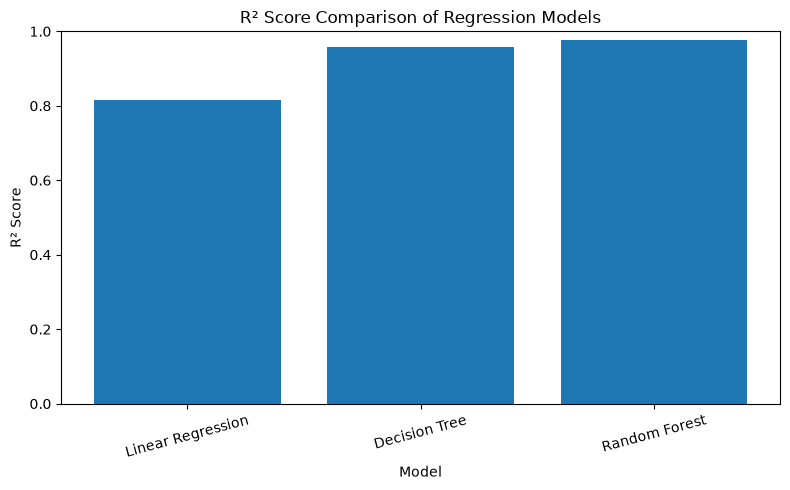

In [568]:
# Plot R² Score comparison

plt.figure(figsize=(8, 5))

plt.bar(
    model_comparison["Model"],
    model_comparison["R2 Score"]
)

plt.title("R² Score Comparison of Regression Models")
plt.xlabel("Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

### Model Selection

Based on the evaluation results, Random Forest Regression provides the lowest prediction error and the highest R² Score among the three tested models.

Therefore, Random Forest Regression is selected as the final model for food demand prediction in the SmartCanteen project.

## 6.8 Actual vs Predicted Demand

The actual food demand values are compared with the demand values predicted by the Random Forest model.

A scatter plot is used to visualize the relationship between actual and predicted demand.

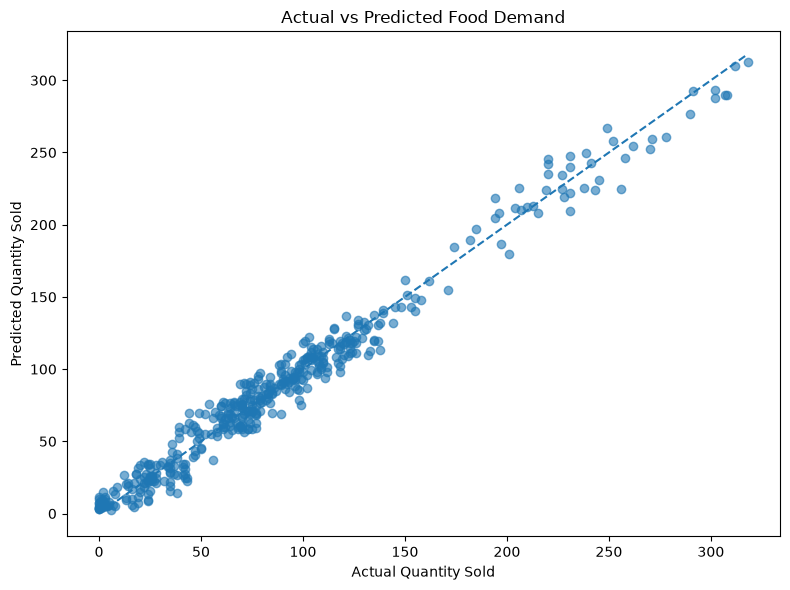

In [569]:
# Compare actual and predicted demand

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    random_forest_predictions,
    alpha=0.6
)

# Reference line
min_value = min(y_test.min(), random_forest_predictions.min())
max_value = max(y_test.max(), random_forest_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Food Demand")
plt.xlabel("Actual Quantity Sold")
plt.ylabel("Predicted Quantity Sold")

plt.tight_layout()
plt.show()

### Interpretation

The points are generally close to the reference line, indicating that the Random Forest model is able to predict food demand reasonably close to the actual values.

The visualization supports the evaluation results obtained from MAE, RMSE, and R² Score.

## 6.9 Prediction Error Analysis

Prediction errors are calculated by comparing the actual demand values with the values predicted by the Random Forest model.

The error distribution helps to understand whether the model predictions have any noticeable overall bias.

In [570]:
# Calculate prediction errors

prediction_errors = y_test - random_forest_predictions

print("Prediction Error Analysis")
print("=" * 50)
print("Mean Error   :", round(prediction_errors.mean(), 4))
print("Minimum Error:", round(prediction_errors.min(), 4))
print("Maximum Error:", round(prediction_errors.max(), 4))

Prediction Error Analysis
Mean Error   : 0.0286
Minimum Error: -25.88
Maximum Error: 31.19


### Error Distribution

The distribution of prediction errors is visualized using a histogram.

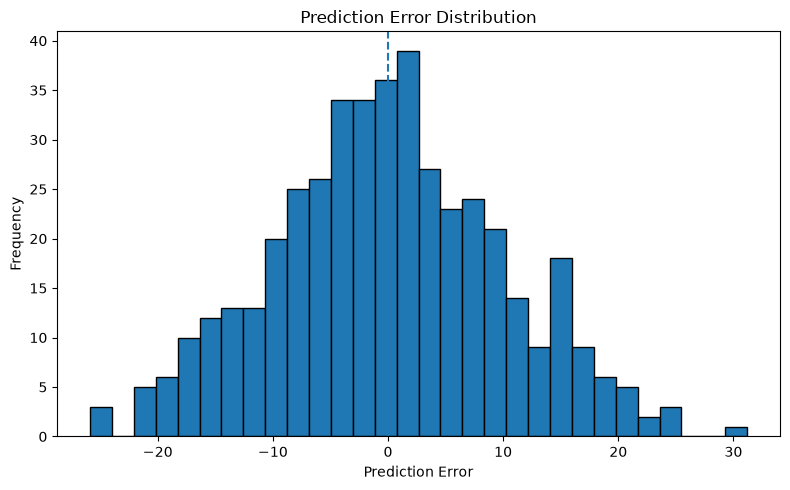

In [571]:
# Plot prediction error distribution

plt.figure(figsize=(8, 5))

plt.hist(
    prediction_errors,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    0,
    linestyle="--"
)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

### Interpretation

The prediction errors are distributed around zero, indicating that the Random Forest model does not show a large overall prediction bias.

Most of the prediction errors are relatively small, which is consistent with the model's MAE, RMSE, and R² Score results.

## 6.10 Feature Importance Analysis

Feature importance is used to understand which input variables contribute most to the Random Forest model's food demand predictions.

This analysis helps identify the factors that have the greatest influence on predicted food demand.

In [572]:
# Extract feature importance from the Random Forest model

rf_model = random_forest_model.named_steps["model"]
rf_preprocessor = random_forest_model.named_steps["preprocessor"]

feature_names = rf_preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15))

,Feature,Importance
20,numerical__Students,0.467991
21,numerical__Price,0.281865
14,categorical__Food_Item_Tea,0.191501
17,numerical__Rainfall_mm,0.018484
18,numerical__Exam_Day,0.009711
8,categorical__Weather_Rainy,0.008113
16,numerical__Temperature,0.004972
19,numerical__Holiday,0.003347
12,categorical__Food_Item_Samosa,0.002857
9,categorical__Weather_Sunny,0.001957


### Feature Importance Visualization

The most important features are visualized using a horizontal bar chart.

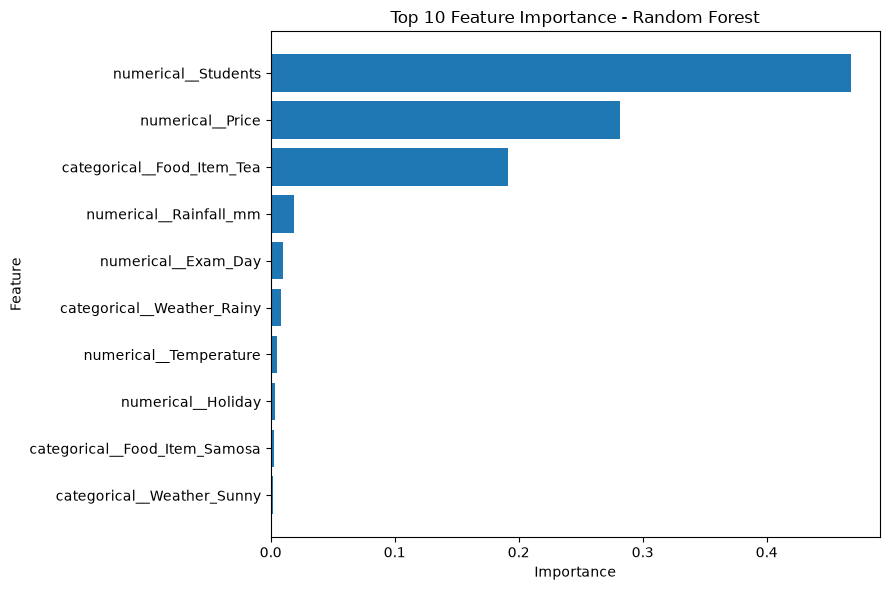

In [573]:
# Plot top 10 feature importances

top_features = feature_importance.head(10).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

### Interpretation

The feature importance analysis shows which variables contribute most to food demand prediction.

Student count and food-related features have a noticeable influence on the predictions, while other factors such as weather, rainfall, temperature, examination days, holidays, and price also contribute to the model.

Feature importance helps in understanding the factors considered by the Random Forest model while predicting food demand.

## 6.11 Saving the Final Model

The Random Forest Regression model is selected as the final model for food demand prediction.

The trained model pipeline is saved as a `.pkl` file so that it can be reused later in the SmartCanteen Streamlit application without retraining the model.

In [574]:
import joblib

# Save the trained Random Forest model pipeline

joblib.dump(
    random_forest_model,
    "demand_model.pkl"
)

print("Final model saved successfully!")
print("Model file: demand_model.pkl")   

Final model saved successfully!
Model file: demand_model.pkl


## 6.12 Machine Learning Summary

The machine learning stage focused on predicting food demand using historical canteen data.

Three regression models were trained and evaluated:

- Linear Regression
- Decision Tree Regression
- Random Forest Regression

The models were evaluated using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

Based on the evaluation results, Random Forest Regression was selected as the final model for food demand prediction.

The final trained model was saved as `demand_model.pkl` and can be reused by the SmartCanteen Streamlit application for future demand predictions.

The machine learning workflow is therefore completed and ready for integration with the application.

# 7. Practical Demand Prediction

The trained Random Forest model is used to predict the expected food demand for a sample canteen situation.

The prediction is based on factors such as day, weather, temperature, rainfall, examination status, holiday status, student count, food item, and price.

## 7.1 Sample Input

A sample scenario is created to demonstrate how the trained model predicts food demand for a selected food item.

In [575]:
# Create a sample input for demand prediction

sample_input = pd.DataFrame({
    "Day": ["Monday"],
    "Weather": ["Sunny"],
    "Temperature": [28],
    "Rainfall_mm": [0.0],
    "Exam_Day": [0],
    "Holiday": [0],
    "Students": [800],
    "Food_Item": ["Tea"],
    "Price": [10]
})

print("Sample Input:")
display(sample_input)

Sample Input:


,Day,Weather,Temperature,Rainfall_mm,Exam_Day,Holiday,Students,Food_Item,Price
0,Monday,Sunny,28,0.0,0,0,800,Tea,10


## 7.2 Generate Demand Prediction

The trained Random Forest model is used to predict the expected quantity of food that may be sold under the given conditions.

In [576]:
# Predict food demand using the trained Random Forest model

predicted_demand = random_forest_model.predict(sample_input)

predicted_quantity = max(0, round(predicted_demand[0]))

print("Predicted Food Demand:", predicted_quantity, "units")

Predicted Food Demand: 211 units


## 7.3 Prediction Result

The model provides the expected food demand based on the selected conditions.

This prediction can help the canteen estimate the required quantity of food to prepare and reduce the chances of over-preparation or shortage.

## 7.4 Prediction Interpretation

For the given sample conditions, the Random Forest model predicts a food demand of approximately **211 units** for Tea.

This means that under the selected conditions, the expected demand for Tea is around 211 units.

The prediction demonstrates how the trained machine learning model can be used to estimate food demand based on different input conditions.

# 8. Conclusion

The SmartCanteen project demonstrates how data science and machine learning can be applied to analyze and predict food demand in a canteen environment.

The project started with the analysis of historical canteen data containing information about food items, student count, weather conditions, temperature, rainfall, examination days, holidays, prices, quantity prepared, quantity sold, waste quantity, and revenue.

Exploratory Data Analysis was performed to understand food demand patterns and relationships between different variables. The analysis showed that food demand varies across food items and is influenced by factors such as student count, weather conditions, examination days, and other input variables.

Three machine learning regression models were trained and evaluated: Linear Regression, Decision Tree Regression, and Random Forest Regression. The models were evaluated using MAE, RMSE, and R² Score. Based on the evaluation results, Random Forest Regression was selected as the final model for food demand prediction.

The trained Random Forest model was then used to generate a practical food demand prediction for a sample canteen situation. The prediction demonstrates how historical data and machine learning can support better estimation of expected food demand.

The final model was saved as `demand_model.pkl` and can be integrated with the SmartCanteen Streamlit application. The application provides a user-friendly interface for demand prediction and basic canteen planning.

Overall, SmartCanteen demonstrates the complete data science workflow from dataset analysis and exploratory visualization to machine learning model training, evaluation, prediction, and application integration.

## 8.1 Project Outcome

The project successfully demonstrates:

- Collection and analysis of canteen-related data.
- Exploratory Data Analysis and visualization.
- Identification of important factors affecting food demand.
- Training and comparison of multiple regression models.
- Food demand prediction using Random Forest Regression.
- Evaluation of machine learning model performance.
- Practical prediction using sample input conditions.
- Saving the trained model for Streamlit application integration.

The project provides a simple and practical example of how data science can be used to support food demand planning in a canteen.